In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc
)

print("Всё работает!")

Всё работает!


In [3]:
df = pd.read_csv("../data/StudentsPerformance.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df["average_score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
) / 3

df["target"] = (df["average_score"] >= 60).astype(int)

df["target"].value_counts()

target
1    715
0    285
Name: count, dtype: int64

In [5]:
X = df[
    [
        "math score",
        "reading score",
        "writing score"
    ]
]

y = df["target"]

In [6]:
df["target"] = (df["math score"] >= 60).astype(int)

X = df[
    [
        "reading score",
        "writing score"
    ]
]

y = df["target"]

In [7]:
print(y.value_counts())
print()
print(y.value_counts(normalize=True))

target
1    677
0    323
Name: count, dtype: int64

target
1    0.677
0    0.323
Name: proportion, dtype: float64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер train:", X_train.shape)
print("Размер test:", X_test.shape)

Размер train: (800, 2)
Размер test: (200, 2)


In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
scaler.fit_transform(X_train)
scaler.transform(X_test)

array([[ 0.07277433,  0.13935136],
       [ 0.41047421,  0.13935136],
       [ 1.82881373,  1.17638473],
       [-0.12984561,  0.07453677],
       [-1.21048524, -0.83286742],
       [ 0.81571408,  0.59305346],
       [ 0.7481741 ,  0.20416594],
       [-1.88588501, -1.35138411],
       [-1.00786531, -1.74027162],
       [ 0.27539426,  0.13935136],
       [ 0.95079403,  0.72268263],
       [-0.26492556, -0.44397991],
       [-1.3455652 , -1.22175494],
       [ 0.27539426,  0.07453677],
       [ 0.20785428, -0.24953615],
       [-0.12984561, -0.37916533],
       [-0.40000552, -0.44397991],
       [-0.40000552, -0.57360908],
       [ 0.95079403,  0.59305346],
       [-0.80524538, -1.02731118],
       [ 0.61309414,  0.72268263],
       [-0.67016542, -0.24953615],
       [-0.40000552, -0.37916533],
       [ 0.41047421,  0.78749722],
       [ 0.7481741 ,  0.33379512],
       [ 0.54555417,  0.33379512],
       [ 1.42357387,  1.56527224],
       [-0.19738558,  0.07453677],
       [-0.12984561,

In [11]:
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [12]:
y_pred = model.predict(X_test_scaled)

In [13]:
y_proba = model.predict_proba(X_test_scaled)

In [14]:
print(y_proba[:10])

[[0.16603854 0.83396146]
 [0.10212366 0.89787634]
 [0.00437061 0.99562939]
 [0.22765615 0.77234385]
 [0.79580198 0.20419802]
 [0.03765807 0.96234193]
 [0.05785747 0.94214253]
 [0.94938588 0.05061412]
 [0.85991298 0.14008702]
 [0.12456474 0.87543526]]


In [15]:
y_proba_positive = y_proba[:, 1]

In [16]:
print(y_proba_positive[:10])

[0.83396146 0.89787634 0.99562939 0.77234385 0.20419802 0.96234193
 0.94214253 0.05061412 0.14008702 0.87543526]


In [17]:
fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    y_proba_positive
)

roc_auc = roc_auc_score(
    y_test,
    y_proba_positive
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8714529914529915


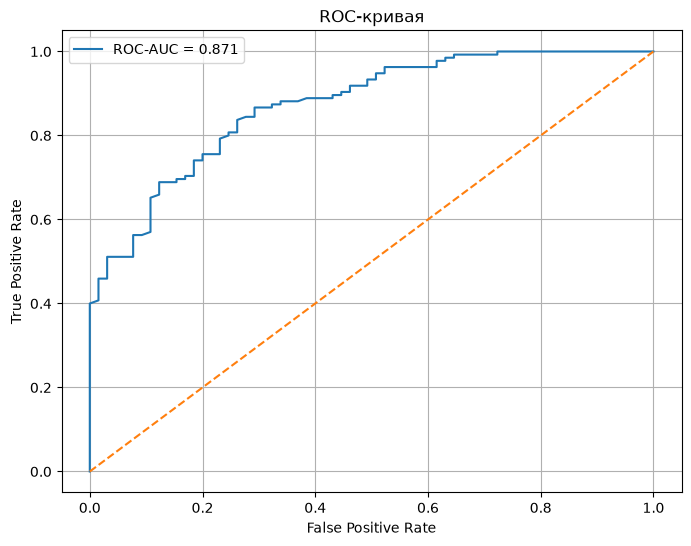

In [18]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая")
plt.legend()
plt.grid()

plt.show()

In [19]:
precision, recall, thresholds_pr = precision_recall_curve(
    y_test,
    y_proba_positive
)

pr_auc = auc(recall, precision)

print("PR-AUC:", pr_auc)

PR-AUC: 0.9350607683017795


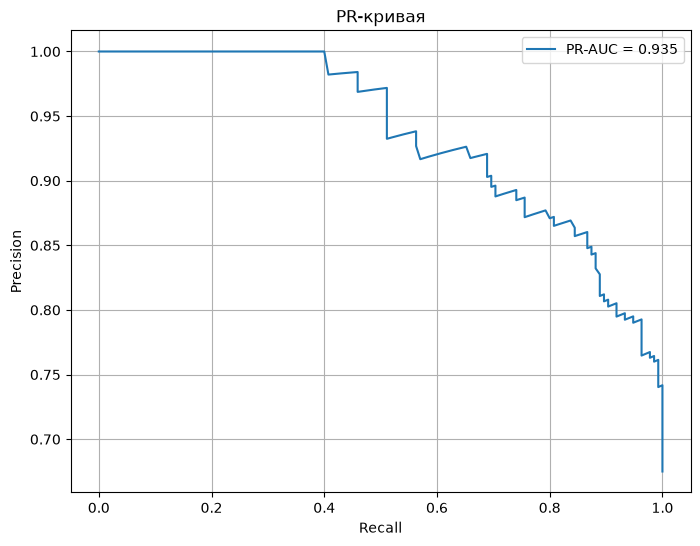

In [20]:
plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"PR-AUC = {pr_auc:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR-кривая")
plt.legend()
plt.grid()

plt.show()

In [21]:
threshold_default = 0.5

y_pred_05 = (
    y_proba_positive >= threshold_default
).astype(int)

In [22]:
print("Accuracy:", accuracy_score(y_test, y_pred_05))
print("Precision:", precision_score(y_test, y_pred_05))
print("Recall:", recall_score(y_test, y_pred_05))
print("F1:", f1_score(y_test, y_pred_05))

Accuracy: 0.79
Precision: 0.803921568627451
Recall: 0.9111111111111111
F1: 0.8541666666666666


In [23]:
print(confusion_matrix(y_test, y_pred_05))

[[ 35  30]
 [ 12 123]]


In [24]:
threshold_new = 0.4

y_pred_new = (
    y_proba_positive >= threshold_new
).astype(int)

In [25]:
print("Accuracy:", accuracy_score(y_test, y_pred_new))
print("Precision:", precision_score(y_test, y_pred_new))
print("Recall:", recall_score(y_test, y_pred_new))
print("F1:", f1_score(y_test, y_pred_new))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_new))

Accuracy: 0.8
Precision: 0.7950310559006211
Recall: 0.9481481481481482
F1: 0.8648648648648649

Confusion matrix:
[[ 32  33]
 [  7 128]]


In [26]:
results = pd.DataFrame({
    "Метрика": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ],
    "Порог 0.5": [
        accuracy_score(y_test, y_pred_05),
        precision_score(y_test, y_pred_05),
        recall_score(y_test, y_pred_05),
        f1_score(y_test, y_pred_05)
    ],
    "Новый порог": [
        accuracy_score(y_test, y_pred_new),
        precision_score(y_test, y_pred_new),
        recall_score(y_test, y_pred_new),
        f1_score(y_test, y_pred_new)
    ]
})

results

,Метрика,Порог 0.5,Новый порог
0,Accuracy,0.790000,0.800000
1,Precision,0.803922,0.795031
2,Recall,0.911111,0.948148
3,F1,0.854167,0.864865


In [27]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

for threshold in thresholds:
    y_pred = (
        y_proba_positive >= threshold
    ).astype(int)

    print(
        f"Threshold={threshold:.1f} | "
        f"Precision={precision_score(y_test, y_pred):.3f} | "
        f"Recall={recall_score(y_test, y_pred):.3f} | "
        f"F1={f1_score(y_test, y_pred):.3f}"
    )

Threshold=0.2 | Precision=0.749 | Recall=0.993 | F1=0.854
Threshold=0.3 | Precision=0.769 | Recall=0.963 | F1=0.855
Threshold=0.4 | Precision=0.795 | Recall=0.948 | F1=0.865
Threshold=0.5 | Precision=0.804 | Recall=0.911 | F1=0.854
Threshold=0.6 | Precision=0.844 | Recall=0.881 | F1=0.862
Threshold=0.7 | Precision=0.868 | Recall=0.830 | F1=0.848
Threshold=0.8 | Precision=0.886 | Recall=0.748 | F1=0.811
